Compare regression and flow matching after 20,000 updates with 30 or 5 eigenvalues on 3,000 shapes: 1,000 triangles, 1,000 convex quadrilaterals, and 1,000 non-convex quadrilaterals. Errors are percentages; the FM mean shape uses 32 aligned draws, and plots show eight draws per example.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "training/regression"))
from spectral_ablation_metrics import align_to

results = root / "results/spectral_ablation_balanced_20261028"
summary = pd.read_csv(results / "summary.csv")
data = np.load(results / "preprocessing.npz")
overall = summary[summary.family == "all"].set_index(["model", "n_eig"])
labels = {"mean_shape_error": "Mean shape (%)", "mean_draw_error": "Mean draw (%)",
          "diversity": "Diversity (%)"}
display((100 * overall[list(labels)]).rename(columns=labels).round(2))

Mean shape (%)  Mean draw (%)  Diversity (%)
model      n_eig                                              
regression 30               6.26           6.26           0.00
           5               11.30          11.30           0.00
flow       30               8.17          11.14          12.37
           5               11.43          14.63          15.66

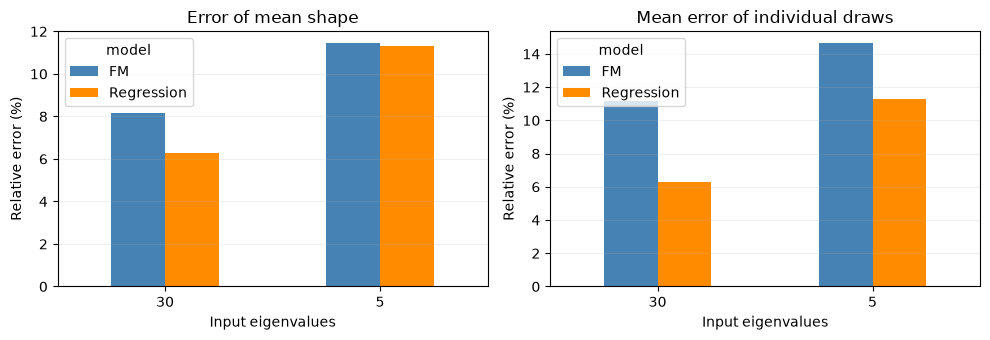

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric, title in zip(axes, ("mean_shape_error", "mean_draw_error"),
                            ("Error of mean shape", "Mean error of individual draws")):
    values = overall[metric].unstack("model").reindex([30, 5])
    values = values.rename(columns={"regression": "Regression", "flow": "FM"})
    (100 * values).plot.bar(ax=ax, rot=0, color=["steelblue", "darkorange"])
    ax.set(title=title, xlabel="Input eigenvalues", ylabel="Relative error (%)")
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

In [3]:
families = summary[summary.family != "all"]
comparison = families.pivot(index=["family", "n_eig"], columns="model", values="mean_shape_error")
comparison = comparison.rename(columns={"regression": "Regression (%)", "flow": "FM mean (%)"})
display((100 * comparison).round(2))

ids = data["test_ids"]
example_ids = [int(np.min(ids[data["families"][ids] == family]))
               for family in ("triangle", "convex_quad", "nonconvex_quad")]
predictions = {}
for model in ("regression", "flow"):
    for n in (30, 5):
        with np.load(results / f"{model}_{n}/test_predictions.npz") as saved:
            predictions[model, n] = saved["samples"]

model                 FM mean (%)  Regression (%)
family         n_eig                             
convex_quad    5            14.53           14.81
               30           11.90            9.72
nonconvex_quad 5            16.44           16.02
               30           10.81            8.40
triangle       5             3.32            3.06
               30            1.79            0.67

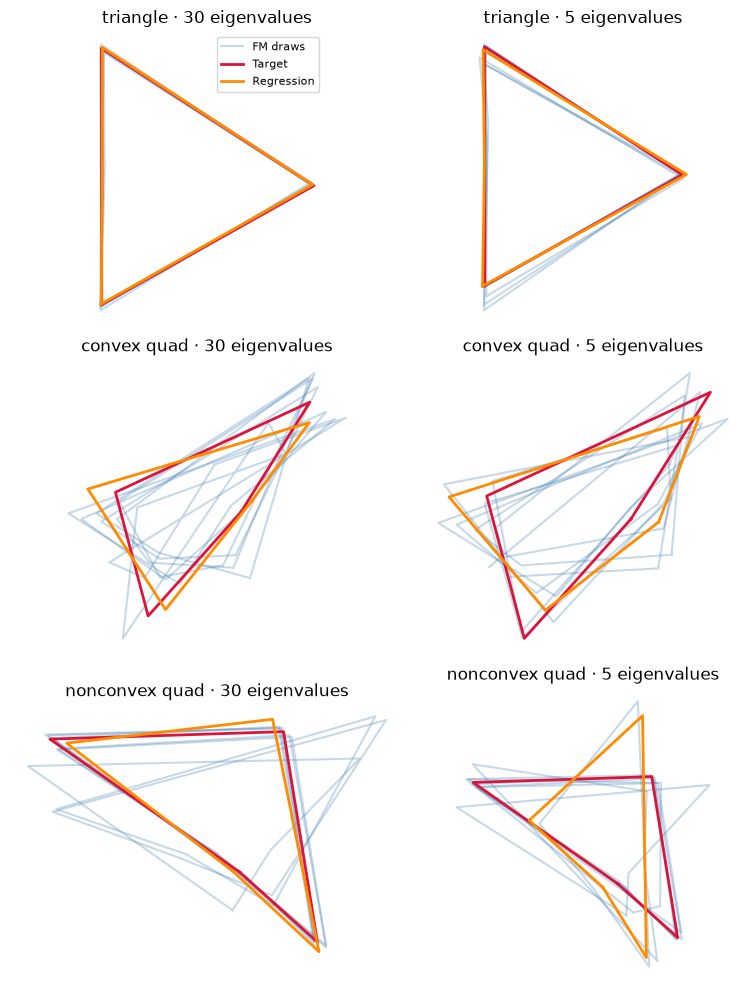

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(8, 10))
for row, drum_id in enumerate(example_ids):
    index = int(np.flatnonzero(ids == drum_id)[0])
    target = data["vertices"][drum_id]
    target = target - target.mean(axis=0)
    for col, n in enumerate((30, 5)):
        ax = axes[row, col]
        draws = align_to(target, predictions["flow", n][index, :8])
        for draw_index, draw in enumerate(draws):
            closed = np.concatenate([draw, draw[:1]])
            ax.plot(*closed.T, color="steelblue", alpha=.3,
                    label="FM draws" if draw_index == 0 else None)
        regression = align_to(target, predictions["regression", n][index, 0])
        for shape, color, label in ((target, "crimson", "Target"),
                                    (regression, "darkorange", "Regression")):
            closed = np.concatenate([shape, shape[:1]])
            ax.plot(*closed.T, color=color, linewidth=2, label=label)
        family = data["families"][drum_id].replace("_", " ")
        ax.set(title=f"{family} · {n} eigenvalues", aspect="equal")
        ax.axis("off")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()